In [1]:

!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

# Fetch Adult Census Income Dataset
adult = fetch_ucirepo(id=2)

# Combine features and target
df = pd.concat(
    [adult.data.features, adult.data.targets],
    axis=1
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [2]:
# Dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Rows:")
display(df.head())

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Shape: (48842, 15)

Column Names:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hour

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



Statistical Summary:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
count,48842.000000,47879,4.884200e+04,48842,48842.000000,48842,47876,48842,48842,48842,48842.000000,48842.000000,48842.000000,48568,48842
unique,NaN,9,NaN,16,NaN,7,15,6,5,2,NaN,NaN,NaN,42,4
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,33906,NaN,15784,NaN,22379,6172,19716,41762,32650,NaN,NaN,NaN,43832,24720
mean,38.643585,NaN,1.896641e+05,NaN,10.078089,NaN,NaN,NaN,NaN,NaN,1079.067626,87.502314,40.422382,NaN,NaN
std,13.710510,NaN,1.056040e+05,NaN,2.570973,NaN,NaN,NaN,NaN,NaN,7452.019058,403.004552,12.391444,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.175505e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.781445e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.376420e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


In [3]:

# Check missing values
print("Missing Values in Each Column:")
print(df.isnull().sum())

# Check unknown values represented by '?'
print("\nUnknown Values ('?') in Each Column:")

for col in df.columns:
    if df[col].dtype == 'object':
        count = (df[col].astype(str).str.strip() == '?').sum()
        if count > 0:
            print(col, ":", count)

# Check duplicate records
print("\nTotal Duplicate Rows:", df.duplicated().sum())

# Check target distribution
print("\nIncome Distribution:")
print(df['income'].value_counts())

print("\nIncome Percentage:")
print(df['income'].value_counts(normalize=True) * 100)


Missing Values in Each Column:
age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
income              0
dtype: int64

Unknown Values ('?') in Each Column:
workclass : 1836
occupation : 1843
native-country : 583

Total Duplicate Rows: 29

Income Distribution:
income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64

Income Percentage:
income
<=50K     50.612178
<=50K.    25.459645
>50K      16.053806
>50K.      7.874370
Name: proportion, dtype: float64


In [4]:

# Step 1: Remove extra spaces from categorical values
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Step 2: Replace '?' with NaN
df.replace('?', np.nan, inplace=True)

# Step 3: Standardize income labels
df['income'] = df['income'].str.replace('.', '', regex=False)

# Step 4: Remove duplicate rows
df.drop_duplicates(inplace=True)

# Step 5: Handle missing categorical values
# Use 'Unknown' to preserve missing information
categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    if col != 'income':
        df[col] = df[col].fillna('Unknown')

# Step 6: Check cleaned dataset
print("Dataset Shape After Cleaning:", df.shape)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nIncome Categories:")
print(df['income'].value_counts())

print("\nDuplicate Rows Remaining:", df.duplicated().sum())


Dataset Shape After Cleaning: (48790, 15)

Missing Values After Cleaning:
age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64

Income Categories:
income
<=50K    37109
>50K     11681
Name: count, dtype: int64

Duplicate Rows Remaining: 0


In [5]:

# Encode target variable
# >50K = 1, <=50K = 0

df['income'] = df['income'].map({
    '<=50K': 0,
    '>50K': 1
})

# Separate features and target
X = df.drop('income', axis=1)
y = df['income']

# Identify numerical and categorical columns
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_cols = X.select_dtypes(include=['object']).columns.tolist()

print("Target Encoding:")
print(y.value_counts())

print("\nNumerical Features:")
print(numeric_cols)

print("\nCategorical Features:")
print(categorical_cols)

print("\nTarget Missing Values:", y.isnull().sum())


Target Encoding:
income
0    37109
1    11681
Name: count, dtype: int64

Numerical Features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical Features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Target Missing Values: 0


In [6]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=408,
    stratify=y
)

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# Fit on training data and transform both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

print("\nTraining Income Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Income Distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training Data Shape: (34153, 108)
Testing Data Shape: (14637, 108)

Training Target Shape: (34153,)
Testing Target Shape: (14637,)

Training Income Distribution:
income
0    76.05774
1    23.94226
Name: proportion, dtype: float64

Testing Income Distribution:
income
0    76.060668
1    23.939332
Name: proportion, dtype: float64


In [7]:

# Outlier detection using IQR method

numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns

print("Outlier Analysis:\n")

for col in numeric_cols:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((X[col] < lower) | (X[col] > upper)).sum()

    print(f"{col}: {count} outliers")


Outlier Analysis:

age: 215 outliers
fnlwgt: 1453 outliers
education-num: 1787 outliers
capital-gain: 4035 outliers
capital-loss: 2282 outliers
hours-per-week: 13486 outliers


MODEL A: LINEAR REGRESSION
--------------------------------
Median Predicted Value: 0.23001247759286486
MSE: 0.11621822396392804
R2 Score: 0.36173346661007266

MODEL B: LOGISTIC REGRESSION
--------------------------------
Accuracy: 0.8512673362027738

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.93      0.90     11133
           1       0.73      0.60      0.66      3504

    accuracy                           0.85     14637
   macro avg       0.81      0.77      0.78     14637
weighted avg       0.84      0.85      0.85     14637


CONFUSION MATRIX
--------------------------------
Rows = Linear Regression
Columns = Logistic Regression
[[7303   15]
 [4437 2882]]


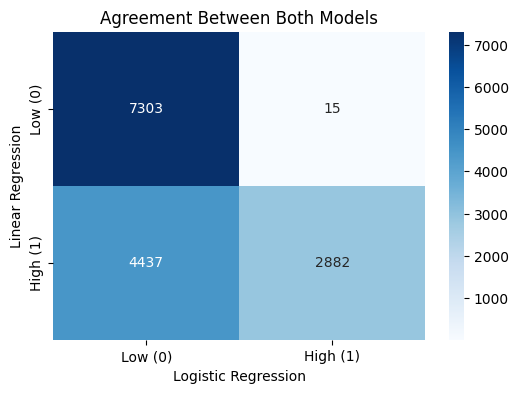


MISMATCH ANALYSIS
--------------------------------
Total Test Cases: 14637
Matching Predictions: 10185
Mismatched Predictions: 4452
Mismatch Percentage: 30.42 %
Agreement Percentage: 69.58 %

FIRST 10 COMPARISONS:


,Actual Income,Linear Prediction,Linear Classification,Logistic Probability,Logistic Classification
0,0,0.486702,1,0.533794,1
1,0,0.521282,1,0.583252,1
2,0,0.179333,0,0.156751,0
3,1,0.350466,1,0.748240,1
4,0,-0.145514,0,0.000618,0
5,0,0.199490,0,0.174817,0
6,0,0.023829,0,0.006721,0
7,0,0.328103,1,0.303515,0
8,0,-0.075156,0,0.004444,0
9,0,-0.108747,0,0.001814,0


In [8]:

# ==========================================
# PART 1 - BUILD
# Adult Census Income Dataset
# ==========================================

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score,
    classification_report, mean_squared_error, r2_score
)
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------------------
# MODEL A: LINEAR REGRESSION (OLS)
# ------------------------------------------

linear_model = LinearRegression()

linear_model.fit(X_train_processed, y_train)

# Predictions
linear_predictions = linear_model.predict(X_test_processed)

# Median threshold
median_value = np.median(linear_predictions)

linear_class = (linear_predictions >= median_value).astype(int)

print("MODEL A: LINEAR REGRESSION")
print("--------------------------------")
print("Median Predicted Value:", median_value)
print("MSE:", mean_squared_error(y_test, linear_predictions))
print("R2 Score:", r2_score(y_test, linear_predictions))


# ------------------------------------------
# MODEL B: LOGISTIC REGRESSION
# ------------------------------------------

logistic_model = LogisticRegression(max_iter=2000)

logistic_model.fit(X_train_processed, y_train)

# Predicted probabilities
logistic_probabilities = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

# Threshold = 0.5
logistic_class = (logistic_probabilities >= 0.5).astype(int)

print("\nMODEL B: LOGISTIC REGRESSION")
print("--------------------------------")
print("Accuracy:", accuracy_score(y_test, logistic_class))

print("\nClassification Report:")
print(classification_report(y_test, logistic_class))


# ------------------------------------------
# MODEL COMPARISON
# ------------------------------------------

# Confusion matrix comparing both approaches
cm = confusion_matrix(linear_class, logistic_class)

print("\nCONFUSION MATRIX")
print("--------------------------------")
print("Rows = Linear Regression")
print("Columns = Logistic Regression")
print(cm)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low (0)', 'High (1)'],
    yticklabels=['Low (0)', 'High (1)']
)
plt.xlabel("Logistic Regression")
plt.ylabel("Linear Regression")
plt.title("Agreement Between Both Models")
plt.show()


# ------------------------------------------
# MISMATCH ANALYSIS
# ------------------------------------------

mismatches = np.sum(linear_class != logistic_class)

total_cases = len(y_test)

mismatch_percentage = (mismatches / total_cases) * 100

agreement = total_cases - mismatches

print("\nMISMATCH ANALYSIS")
print("--------------------------------")
print("Total Test Cases:", total_cases)
print("Matching Predictions:", agreement)
print("Mismatched Predictions:", mismatches)
print("Mismatch Percentage:", round(mismatch_percentage, 2), "%")
print("Agreement Percentage:", round(
    (agreement / total_cases) * 100, 2
), "%")


# ------------------------------------------
# FINAL COMPARISON TABLE
# ------------------------------------------

comparison = pd.DataFrame({
    'Actual Income': y_test.values,
    'Linear Prediction': linear_predictions,
    'Linear Classification': linear_class,
    'Logistic Probability': logistic_probabilities,
    'Logistic Classification': logistic_class
})

print("\nFIRST 10 COMPARISONS:")
display(comparison.head(10))


In [9]:

import statsmodels.api as sm
import statsmodels.formula.api as smf
import pandas as pd

# Prepare data for Simpson's Paradox analysis
simpson_df = df.copy()

# Rename columns for formula compatibility
simpson_df.columns = simpson_df.columns.str.replace('-', '_')

# Select relevant variables
simpson_df = simpson_df[
    ['income', 'sex', 'education_num', 'age',
     'hours_per_week', 'capital_gain', 'capital_loss']
].copy()

# Remove missing values
simpson_df = simpson_df.dropna()

# Define logistic regression formula
formula = """
income ~ education_num + age + hours_per_week
+ capital_gain + capital_loss + C(sex)
"""

# Full dataset model
full_model = smf.glm(
    formula=formula,
    data=simpson_df,
    family=sm.families.Binomial()
).fit()

# Female subgroup model
female_df = simpson_df[simpson_df['sex'] == 'Female']

female_model = smf.glm(
    formula="""
    income ~ education_num + age + hours_per_week
    + capital_gain + capital_loss
    """,
    data=female_df,
    family=sm.families.Binomial()
).fit()

# Male subgroup model
male_df = simpson_df[simpson_df['sex'] == 'Male']

male_model = smf.glm(
    formula="""
    income ~ education_num + age + hours_per_week
    + capital_gain + capital_loss
    """,
    data=male_df,
    family=sm.families.Binomial()
).fit()

# Extract education-num coefficients
results = []

for name, model in [
    ('Full Dataset', full_model),
    ('Female', female_model),
    ('Male', male_model)
]:
    results.append({
        'Group': name,
        'Coefficient': model.params['education_num'],
        'Lower CI': model.conf_int().loc['education_num', 0],
        'Upper CI': model.conf_int().loc['education_num', 1],
        'P-value': model.pvalues['education_num']
    })

# Display comparison
simpson_results = pd.DataFrame(results)

print("SIMPSON'S PARADOX - REGRESSION RESULTS")
display(simpson_results)

print("\nSample Sizes:")
print("Full Dataset:", len(simpson_df))
print("Female:", len(female_df))
print("Male:", len(male_df))


SIMPSON'S PARADOX - REGRESSION RESULTS


,Group,Coefficient,Lower CI,Upper CI,P-value
0,Full Dataset,0.333847,0.322729,0.344966,0.000000e+00
1,Female,0.363815,0.337151,0.390479,1.491399e-157
2,Male,0.329074,0.316789,0.341358,0.000000e+00



Sample Sizes:
Full Dataset: 48790
Female: 16176
Male: 32614


In [10]:

import statsmodels.api as sm
import statsmodels.formula.api as smf
import pandas as pd
import numpy as np

# Prepare dataset
ovb_df = df.copy()
ovb_df.columns = ovb_df.columns.str.replace('-', '_')

# Full model with education_num
full_formula = """
income ~ age + education_num + hours_per_week
+ capital_gain + capital_loss + C(sex) + C(race)
"""

full_ovb_model = smf.glm(
    formula=full_formula,
    data=ovb_df,
    family=sm.families.Binomial()
).fit()

# Reduced model without education_num
reduced_formula = """
income ~ age + hours_per_week
+ capital_gain + capital_loss + C(sex) + C(race)
"""

reduced_ovb_model = smf.glm(
    formula=reduced_formula,
    data=ovb_df,
    family=sm.families.Binomial()
).fit()

# Compare coefficients of common numerical predictors
predictors = [
    'age',
    'hours_per_week',
    'capital_gain',
    'capital_loss'
]

comparison_results = []

for predictor in predictors:

    full_coef = full_ovb_model.params[predictor]
    reduced_coef = reduced_ovb_model.params[predictor]

    if abs(full_coef) > 1e-10:
        percentage_change = (
            (reduced_coef - full_coef) / abs(full_coef)
        ) * 100
    else:
        percentage_change = np.nan

    comparison_results.append({
        'Predictor': predictor,
        'Full Model Coefficient': full_coef,
        'Reduced Model Coefficient': reduced_coef,
        'Percentage Change (%)': percentage_change
    })

# Display results
ovb_results = pd.DataFrame(comparison_results)

print("OMITTED VARIABLE BIAS ANALYSIS")
print("Variable Removed: education_num\n")

display(ovb_results.round(4))

# Identify predictor with maximum absolute percentage change
max_index = ovb_results['Percentage Change (%)'].abs().idxmax()

print("\nPredictor with Maximum Coefficient Change:")
print(ovb_results.loc[max_index, 'Predictor'])

print(
    "Maximum Percentage Change:",
    round(
        abs(ovb_results.loc[max_index, 'Percentage Change (%)']), 2
    ), "%"
)


OMITTED VARIABLE BIAS ANALYSIS
Variable Removed: education_num



,Predictor,Full Model Coefficient,Reduced Model Coefficient,Percentage Change (%)
0,age,0.0407,0.0370,-9.1745
1,hours_per_week,0.0329,0.0368,11.6589
2,capital_gain,0.0003,0.0003,3.2248
3,capital_loss,0.0007,0.0007,12.1304



Predictor with Maximum Coefficient Change:
capital_loss
Maximum Percentage Change: 12.13 %


In [11]:

# ==========================================
# PART 2.3 - ADVERSARIAL SUBSET CONSTRUCTION
# ==========================================

import pandas as pd
import numpy as np

# Create test dataset with actual and predicted values
adversarial_df = X_test.copy()

adversarial_df['Actual_Income'] = y_test.values
adversarial_df['Predicted_Probability'] = logistic_probabilities

# Identify highly confident wrong predictions
false_positives = adversarial_df[
    (adversarial_df['Predicted_Probability'] >= 0.75) &
    (adversarial_df['Actual_Income'] == 0)
]

false_negatives = adversarial_df[
    (adversarial_df['Predicted_Probability'] <= 0.25) &
    (adversarial_df['Actual_Income'] == 1)
]

# Combine both types of errors
wrong_predictions = pd.concat([
    false_positives,
    false_negatives
])

# Total count and percentage
total_wrong = len(wrong_predictions)
total_test = len(adversarial_df)

percentage_wrong = (total_wrong / total_test) * 100

print("ADVERSARIAL SUBSET ANALYSIS")
print("--------------------------------")
print("False Positives:", len(false_positives))
print("False Negatives:", len(false_negatives))
print("Total High-Confidence Wrong Predictions:", total_wrong)
print("Percentage of Test Set:", round(percentage_wrong, 2), "%")

# Randomly select up to 50 cases
adversarial_sample = wrong_predictions.sample(
    n=min(50, total_wrong),
    random_state=408
)

print("\nSelected Adversarial Rows:", len(adversarial_sample))

# Compare demographics with full test set
print("\nAGE COMPARISON")
print("--------------------------------")
print("Full Test Set:")
print(adversarial_df['age'].describe())

print("\nAdversarial Subset:")
print(adversarial_sample['age'].describe())

print("\nGENDER DISTRIBUTION - FULL TEST SET")
print(adversarial_df['sex'].value_counts(normalize=True) * 100)

print("\nGENDER DISTRIBUTION - ADVERSARIAL SUBSET")
print(adversarial_sample['sex'].value_counts(normalize=True) * 100)

print("\nRACE DISTRIBUTION - ADVERSARIAL SUBSET")
print(adversarial_sample['race'].value_counts(normalize=True) * 100)

# Identify common characteristics
print("\nCOMMON CHARACTERISTICS")
print("--------------------------------")

print(
    "Percentage aged 40 or above:",
    round((adversarial_sample['age'] >= 40).mean() * 100, 2), "%"
)

print(
    "Percentage with capital gain > 0:",
    round((adversarial_sample['capital-gain'] > 0).mean() * 100, 2), "%"
)

print(
    "Percentage working more than 40 hours:",
    round((adversarial_sample['hours-per-week'] > 40).mean() * 100, 2), "%"
)

# Display selected rows
print("\nFIRST 10 ADVERSARIAL CASES")
display(adversarial_sample.head(10))


ADVERSARIAL SUBSET ANALYSIS
--------------------------------
False Positives: 160
False Negatives: 587
Total High-Confidence Wrong Predictions: 747
Percentage of Test Set: 5.1 %

Selected Adversarial Rows: 50

AGE COMPARISON
--------------------------------
Full Test Set:
count    14637.000000
mean        38.551479
std         13.726097
min         17.000000
25%         28.000000
50%         37.000000
75%         48.000000
max         90.000000
Name: age, dtype: float64

Adversarial Subset:
count    50.00000
mean     44.02000
std       9.78439
min      24.00000
25%      36.25000
50%      44.50000
75%      50.00000
max      64.00000
Name: age, dtype: float64

GENDER DISTRIBUTION - FULL TEST SET
sex
Male      66.195259
Female    33.804741
Name: proportion, dtype: float64

GENDER DISTRIBUTION - ADVERSARIAL SUBSET
sex
Male      76.0
Female    24.0
Name: proportion, dtype: float64

RACE DISTRIBUTION - ADVERSARIAL SUBSET
race
White                 92.0
Black                  6.0
Asian-Pac-Is

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Actual_Income,Predicted_Probability
29871,40,Private,360884,Some-college,10,Never-married,Tech-support,Not-in-family,White,Female,0,0,50,United-States,1,0.060962
5917,39,Private,186183,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,1,0.247108
34176,64,Private,146674,HS-grad,9,Married-civ-spouse,Other-service,Husband,Black,Male,0,0,40,Unknown,1,0.128853
46942,39,Private,101192,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,1,0.235313
24742,24,State-gov,197731,HS-grad,9,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,49,United-States,1,0.136572
2570,54,Unknown,124993,HS-grad,9,Married-civ-spouse,Unknown,Husband,White,Male,0,0,40,United-States,1,0.174132
41161,31,Private,140206,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,1,0.153603
610,52,Private,200853,Masters,14,Divorced,Prof-specialty,Not-in-family,White,Female,6849,0,60,United-States,0,0.813326
47079,45,Private,175600,Masters,14,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,60,United-States,0,0.850430
37598,58,Private,219504,12th,8,Divorced,Transport-moving,Unmarried,Black,Male,0,0,45,United-States,1,0.033135


FAIRNESS METRICS AT DIFFERENT THRESHOLDS


,Threshold,DP,EO,PP
0,0.05,0.4507,0.4166,0.7378
1,0.15,0.3065,0.2520,0.9456
2,0.25,0.2832,0.2257,0.9828
3,0.35,0.2724,0.2148,0.9934
4,0.45,0.2711,0.2146,0.9932
5,0.55,0.2735,0.2199,0.9897
6,0.65,0.2794,0.2303,0.9866
7,0.75,0.3051,0.2825,0.9746
8,0.85,0.2918,0.2641,0.9874
9,0.95,0.3221,0.2347,1.0023


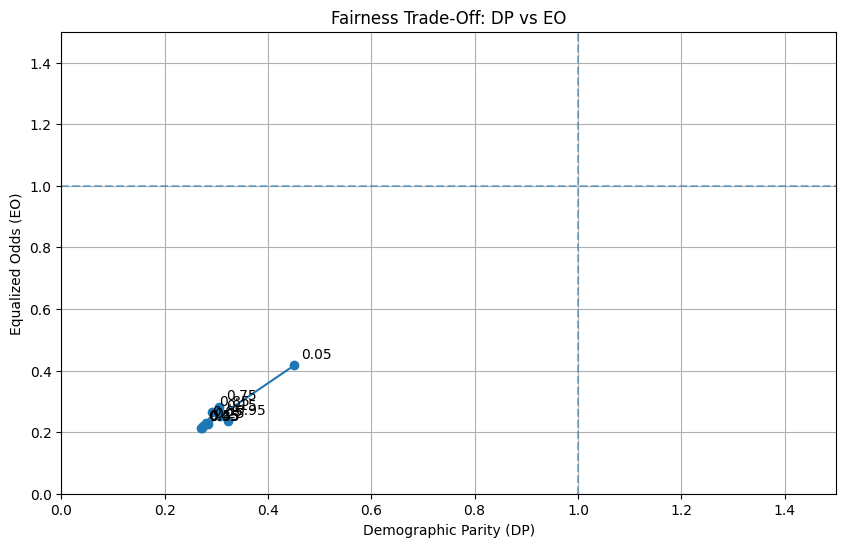


GROUP DISTRIBUTION
------------------------------
Female Records: 4948
Male Records: 9689

Ideal value for DP, EO and PP = 1.0


In [12]:

# ==========================================
# PART 2.4 - FAIRNESS TRADE-OFF ANALYSIS
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare test data
fairness_df = X_test.copy()

fairness_df['actual'] = y_test.values
fairness_df['probability'] = logistic_probabilities

# Define demographic groups
group_A = 'Female'
group_B = 'Male'

thresholds = np.round(np.arange(0.05, 1.00, 0.10), 2)

results = []

# Helper function for safe division
def safe_ratio(a, b):
    if b == 0 or np.isnan(b):
        return np.nan
    return a / b

# Calculate fairness metrics at each threshold
for threshold in thresholds:

    fairness_df['predicted'] = (
        fairness_df['probability'] >= threshold
    ).astype(int)

    A = fairness_df[fairness_df['sex'] == group_A]
    B = fairness_df[fairness_df['sex'] == group_B]

    # Demographic Parity
    dp_A = A['predicted'].mean()
    dp_B = B['predicted'].mean()

    DP = safe_ratio(dp_A, dp_B)

    # True Positive Rate
    tpr_A = (
        A.loc[A['actual'] == 1, 'predicted'].mean()
    )

    tpr_B = (
        B.loc[B['actual'] == 1, 'predicted'].mean()
    )

    # False Positive Rate
    fpr_A = (
        A.loc[A['actual'] == 0, 'predicted'].mean()
    )

    fpr_B = (
        B.loc[B['actual'] == 0, 'predicted'].mean()
    )

    # Equalized Odds
    EO = min(
        safe_ratio(tpr_A, tpr_B),
        safe_ratio(fpr_A, fpr_B)
    ) if not np.isnan(safe_ratio(tpr_A, tpr_B)) and not np.isnan(safe_ratio(fpr_A, fpr_B)) else np.nan

    # Predictive Parity (Precision)
    precision_A = (
        A.loc[A['predicted'] == 1, 'actual'].mean()
    )

    precision_B = (
        B.loc[B['predicted'] == 1, 'actual'].mean()
    )

    PP = safe_ratio(precision_A, precision_B)

    results.append({
        'Threshold': threshold,
        'DP': DP,
        'EO': EO,
        'PP': PP
    })

# Create results table
fairness_results = pd.DataFrame(results)

print("FAIRNESS METRICS AT DIFFERENT THRESHOLDS")
display(fairness_results.round(4))


# ------------------------------------------
# TRADE-OFF CHART
# ------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    fairness_results['DP'],
    fairness_results['EO'],
    marker='o',
    linestyle='-'
)

for i in range(len(fairness_results)):
    plt.annotate(
        str(fairness_results['Threshold'].iloc[i]),
        (
            fairness_results['DP'].iloc[i],
            fairness_results['EO'].iloc[i]
        ),
        xytext=(5, 5),
        textcoords='offset points'
    )

plt.axvline(1.0, linestyle='--', alpha=0.5)
plt.axhline(1.0, linestyle='--', alpha=0.5)

plt.xlabel('Demographic Parity (DP)')
plt.ylabel('Equalized Odds (EO)')
plt.title('Fairness Trade-Off: DP vs EO')

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)

plt.grid(True)
plt.show()


# ------------------------------------------
# DISPLAY GROUP INFORMATION
# ------------------------------------------

print("\nGROUP DISTRIBUTION")
print("------------------------------")

print("Female Records:", len(fairness_df[fairness_df['sex'] == group_A]))
print("Male Records:", len(fairness_df[fairness_df['sex'] == group_B]))

print("\nIdeal value for DP, EO and PP = 1.0")
